In [2]:
import pandas as pd

df = pd.read_csv(
     "household_power_consumption.txt",
     sep = ";",
     na_values = "?",
     low_memory = False,

)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"], dayfirst=True
)
df = df.drop(columns=["Date", "Time"]).set_index("datetime")

df.info()
print(df.isna().sum())
df.head()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:
# 1) هل الناقص صفوف كاملة؟
print(df.isna().sum(axis=1).value_counts())



0    2049280
7      25979
Name: count, dtype: int64


In [4]:
# 2) التكرار في الفهرس
print("مكرر:", df.index.duplicated().sum())
df = df[~df.index.duplicated(keep="first")]



مكرر: 0


In [5]:
# 3) هل هناك دقائق مفقودة تمامًا من السلسلة؟
full_idx = pd.date_range(df.index.min(), df.index.max(), freq="min")
print("دقائق مفقودة من الفهرس:", len(full_idx) - len(df))
df = df.reindex(full_idx)



دقائق مفقودة من الفهرس: 0


In [6]:
# 4) أطوال فترات الانقطاع
na = df["Global_active_power"].isna()
grp = (na != na.shift()).cumsum()
gaps = na.groupby(grp).agg(["first", "size"])
gaps = gaps[gaps["first"]]["size"]
print(gaps.describe())
print(gaps.sort_values(ascending=False).head(10))



count      71.000000
mean      365.901408
std      1251.468043
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max      7226.000000
Name: size, dtype: float64
Global_active_power
138    7226
140    5237
14     3723
100    3305
118    3129
126    2027
104     891
32       83
78       70
34       47
Name: size, dtype: int64


In [7]:
# 5) فحص القيم الشاذة
print(df.describe().T)

                           count        mean       std      min      25%  \
Global_active_power    2049280.0    1.091615  1.057294    0.076    0.308   
Global_reactive_power  2049280.0    0.123714  0.112722    0.000    0.048   
Voltage                2049280.0  240.839858  3.239987  223.200  238.990   
Global_intensity       2049280.0    4.627759  4.444396    0.200    1.400   
Sub_metering_1         2049280.0    1.121923  6.153031    0.000    0.000   
Sub_metering_2         2049280.0    1.298520  5.822026    0.000    0.000   
Sub_metering_3         2049280.0    6.458447  8.437154    0.000    0.000   

                           50%      75%      max  
Global_active_power      0.602    1.528   11.122  
Global_reactive_power    0.100    0.194    1.390  
Voltage                241.010  242.890  254.150  
Global_intensity         2.600    6.400   48.400  
Sub_metering_1           0.000    0.000   88.000  
Sub_metering_2           0.000    1.000   80.000  
Sub_metering_3           1.000   1

In [9]:
df["Sub_metering_4"] = (
    df["Global_active_power"] * 1000 / 60
    - df["Sub_metering_1"] - df["Sub_metering_2"] - df["Sub_metering_3"]
)

In [10]:
# أعد حساب العمود المشتق لاحقًا، لذا نحذفه الآن
df = df.drop(columns=["Sub_metering_4"], errors="ignore")

na = df["Global_active_power"].isna()
grp = (na != na.shift()).cumsum()
gap_len = na.groupby(grp).transform("size")
short_gap = na & (gap_len <= 60)

filled = df.interpolate(method="time", limit_area="inside")
df_clean = df.copy()
df_clean.loc[short_gap, df.columns] = filled.loc[short_gap, df.columns]

print("ناقص قبل:", df["Global_active_power"].isna().sum())
print("ناقص بعد:", df_clean["Global_active_power"].isna().sum())

# العمود المشتق: الطاقة غير المقاسة بالعدادات الفرعية (واط-ساعة)
df_clean["Sub_metering_4"] = (
    df_clean["Global_active_power"] * 1000 / 60
    - df_clean["Sub_metering_1"]
    - df_clean["Sub_metering_2"]
    - df_clean["Sub_metering_3"]
)
print("قيم سالبة في Sub_metering_4:", (df_clean["Sub_metering_4"] < 0).sum())
print(df_clean["Sub_metering_4"].describe())

ناقص قبل: 25979
ناقص بعد: 25691
قيم سالبة في Sub_metering_4: 1050
count    2.049568e+06
mean     9.315289e+00
std      9.586089e+00
min     -2.400000e+00
25%      3.800000e+00
50%      5.500000e+00
75%      1.036667e+01
max      1.248333e+02
Name: Sub_metering_4, dtype: float64


In [11]:

import matplotlib.pyplot as plt

df_clean["Sub_metering_4"] = df_clean["Sub_metering_4"].clip(lower=0)

sub_cols = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3", "Sub_metering_4"]
hourly = df_clean[["Global_active_power"] + sub_cols].resample("h").mean()
hourly[sub_cols] = hourly[sub_cols] * 60 / 1000      # Wh/min -> kWh/hour
hourly = hourly.rename(columns={"Global_active_power": "total_kWh"})  # متوسط kW خلال ساعة = kWh

hourly["hour"] = hourly.index.hour
hourly["dow"] = hourly.index.dayofweek               # 0 = الاثنين
hourly["month"] = hourly.index.month
hourly["is_weekend"] = hourly["dow"] >= 5
hourly.head()

,total_kWh,Sub_metering_1,Sub_metering_2,Sub_metering_3,Sub_metering_4,hour,dow,month,is_weekend
2006-12-16 17:00:00,4.222889,0.0,0.031667,1.011667,3.179556,17,5,12,True
2006-12-16 18:00:00,3.632200,0.0,0.403000,1.012000,2.217200,18,5,12,True
2006-12-16 19:00:00,3.400233,0.0,0.086000,1.001000,2.313233,19,5,12,True
2006-12-16 20:00:00,3.268567,0.0,0.000000,1.007000,2.261567,20,5,12,True
2006-12-16 21:00:00,3.056467,0.0,0.025000,1.033000,1.998467,21,5,12,True


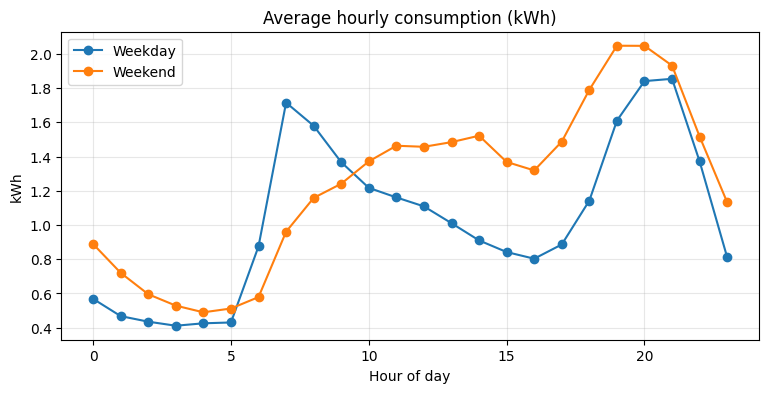

ساعة الذروة: {'Weekday': 21, 'Weekend': 19}


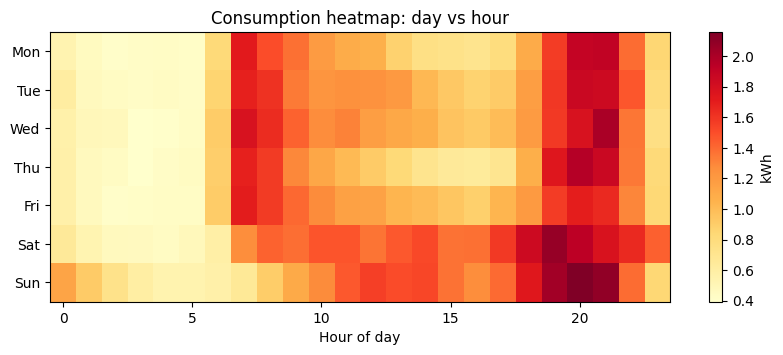

In [23]:
prof = hourly.groupby(["is_weekend", "hour"])["total_kWh"].mean().unstack(0)
prof.columns = ["Weekday", "Weekend"]
prof.plot(figsize=(9, 4), marker="o", title="Average hourly consumption (kWh)")
plt.xlabel("Hour of day"); plt.ylabel("kWh"); plt.grid(alpha=.3); plt.savefig("weekday_vs_weekend.png", dpi=150, bbox_inches="tight")
plt.show()
print("ساعة الذروة:", prof.idxmax().to_dict())

heat = hourly.pivot_table(index="dow", columns="hour", values="total_kWh", aggfunc="mean")
plt.figure(figsize=(10, 3.5))
plt.imshow(heat, aspect="auto", cmap="YlOrRd")
plt.colorbar(label="kWh")
plt.yticks(range(7), ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
plt.xlabel("Hour of day"); plt.title("Consumption heatmap: day vs hour"); plt.savefig("heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

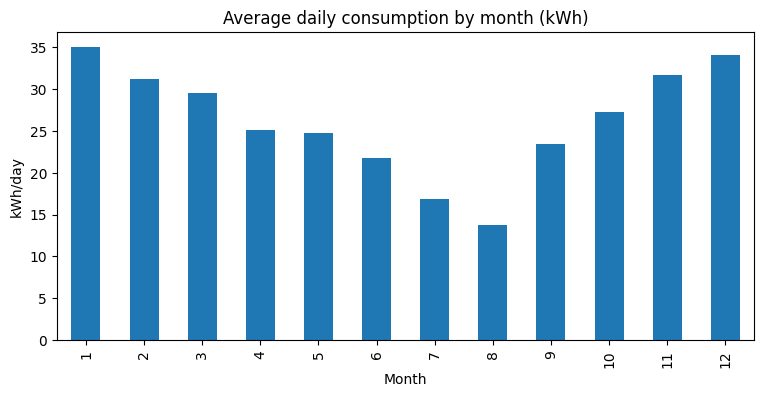

أعلى شهر: 1 35.1 | أدنى شهر: 8 13.8


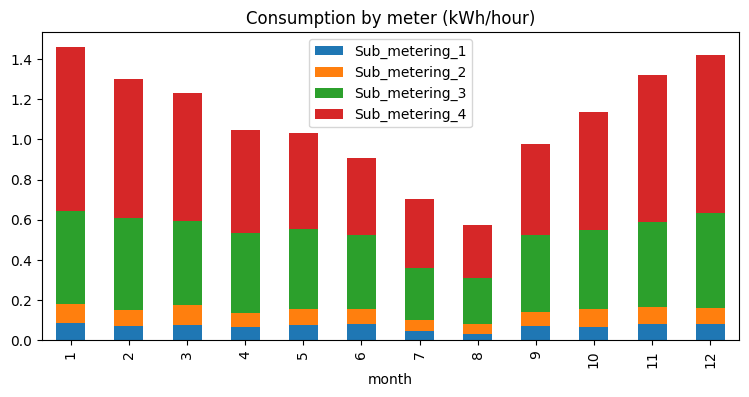

Sub_metering_1     6.2
Sub_metering_2     7.2
Sub_metering_3    35.8
Sub_metering_4    50.8
dtype: float64


In [24]:
full = hourly.loc["2007-01":"2010-10"]

monthly = full.groupby("month")["total_kWh"].mean() * 24     # متوسط kWh لليوم
monthly.plot(kind="bar", figsize=(9, 4), title="Average daily consumption by month (kWh)")
plt.xlabel("Month"); plt.ylabel("kWh/day"); plt.savefig("monthly.png", dpi=150, bbox_inches="tight")
plt.show()
print("أعلى شهر:", monthly.idxmax(), round(monthly.max(), 1),
      "| أدنى شهر:", monthly.idxmin(), round(monthly.min(), 1))

share = full.groupby("month")[sub_cols].mean()
share.plot(kind="bar", stacked=True, figsize=(9, 4),
           title="Consumption by meter (kWh/hour)")
plt.savefig("meters.png", dpi=150, bbox_inches="tight")
plt.show()

print((full[sub_cols].sum() / full[sub_cols].sum().sum() * 100).round(1))

In [22]:
full = hourly.loc["2007-01":"2010-10"].copy()
full["peak"] = full["hour"].between(18, 21)        # 18:00 - 21:59

# حصة ساعات المساء من الاستهلاك الكلي
tmp = full.assign(peak_kwh=full["total_kWh"].where(full["peak"]))
g = tmp.groupby("is_weekend")
print("حصة 18-22 من الاستهلاك (%):")
print((g["peak_kwh"].sum() / g["total_kWh"].sum() * 100).round(1))

# متوسط كل عداد داخل الذروة وخارجها (kWh/ساعة)
print(full.groupby("peak")[sub_cols].mean().round(3))

حصة 18-22 من الاستهلاك (%):
is_weekend
False    26.0
True     26.6
dtype: float64
       Sub_metering_1  Sub_metering_2  Sub_metering_3  Sub_metering_4
peak                                                                 
False           0.052           0.070           0.378           0.457
True            0.143           0.114           0.428           1.009
